In [1]:
import xarray as xr
import numpy as np
import pandas as pd
from scipy import ndimage
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib as mpl
import cartopy.crs as ccrs
import warnings
import time

from mhw_detection_functions import *

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

## NOAA OI SST V2 High Resolution Dataset

Source: https://psl.noaa.gov/data/gridded/data.noaa.oisst.v2.highres.html

Dataset Specifications:
- Daily values from 1981/09 to 2026/09
- 0.25 degree latitude x 0.25 degree longitude global grid (1440x720)

In [2]:
raw = xr.open_dataset('data/noaa_oisst/noaa_oisst_aus_1981_2026.nc')
raw

<xarray.Dataset>
Dimensions:  (time: 16461, lon: 280, lat: 220)
Coordinates:
  * time     (time) datetime64[ns] 1981-09-01 1981-09-02 ... 2026-09-25
  * lon      (lon) float32 110.1 110.4 110.6 110.9 ... 179.1 179.4 179.6 179.9
  * lat      (lat) float32 -54.88 -54.62 -54.38 -54.12 ... -0.625 -0.375 -0.125
Data variables:
    sst      (time, lat, lon) float32 ...
Attributes:
    CDI:            Climate Data Interface version 1.9.10 (https://mpimet.mpg...
    source:         NOAA/NCDC  ftp://eclipse.ncdc.noaa.gov/pub/OI-daily-v2/
    institution:    NOAA/NCDC
    Conventions:    CF-1.5
    title:          NOAA High-resolution Blended Analysis: Daily Values using...
    dataset_title:  NOAA Daily Optimum Interpolation Sea Surface Temperature
    References:     https://www.psl.noaa.gov/data/gridded/data.noaa.oisst.v2....
    comment:        Reynolds, et al.(2007) Daily High-Resolution-Blended Anal...
    CDO:            Climate Data Operators version 1.9.10 (https://mpimet.mpg...
    history:        27-Sep-2026 03:32:35 Subset NOAA/PSL

In [3]:
var_names = {"sst": "temp"}
raw = raw.rename(var_names)

daily = resample_daily(raw, var="temp")

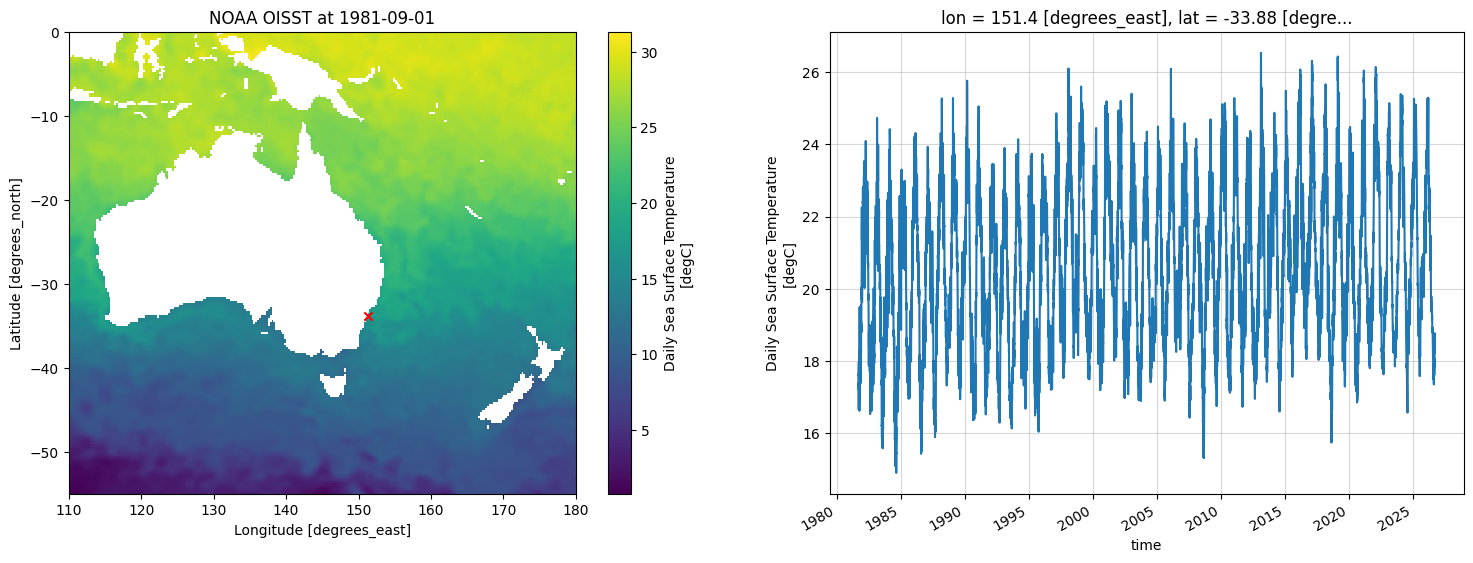

In [4]:
# location off the coast of Sydney, chosen based on proximity to IMOS dataset:
# data/IMOS_ANMN-NSW_TZ_20060608_ORS065_FV02_TEMP-gridded-timeseries_END-20251203_C-20260523.nc
lon_sel, lat_sel = 151.3, -33.8

fig, (ax1, ax2) = plt.subplots(1,2, figsize=(18, 6))

daily.isel(time=0).plot(cmap='viridis', ax=ax1)
ax1.scatter(lon_sel, lat_sel, marker='x', c='red')
ax1.set_title(f"NOAA OISST at {daily.isel(time=0).time.dt.strftime('%Y-%m-%d').item()}")

daily.sel(lat=lat_sel, lon=lon_sel, method='nearest').plot(ax=ax2)
ax2.grid(alpha=0.5)

## Q: do the same relationships hold when a simulated random SST time series is used? What do the distributions of intensity and duration look like?

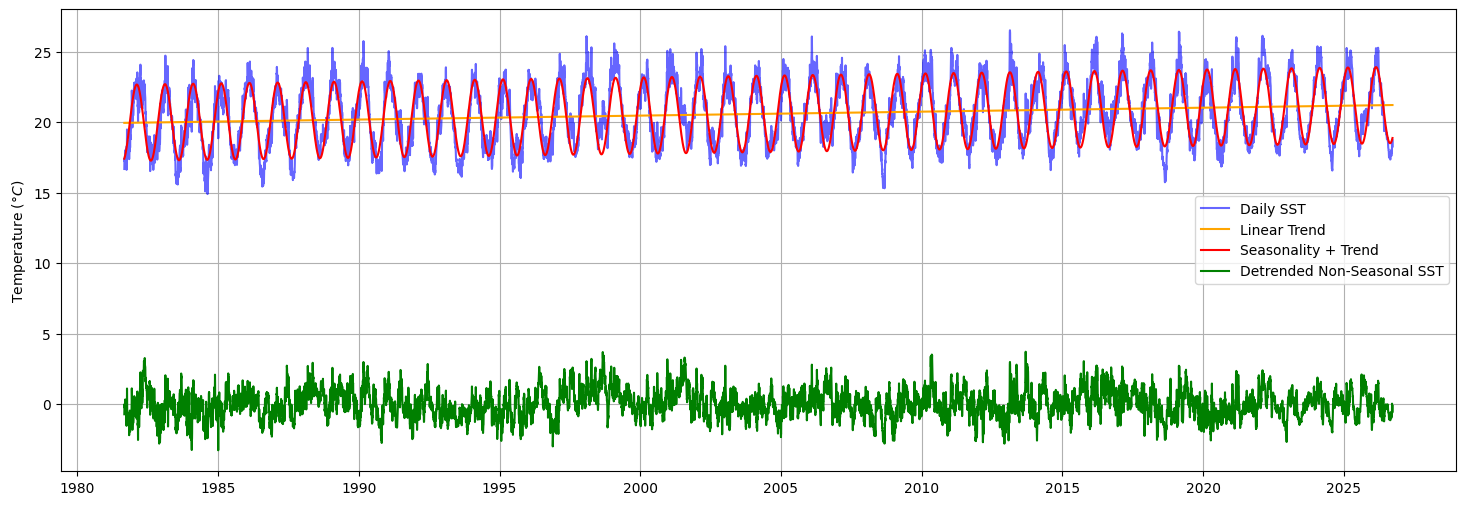

In [5]:
syd_daily = daily.sel(lat=lat_sel, lon=lon_sel, method='nearest')#.sel(time=slice('1981-09-01','1991-09-01'))

# degree 1 polynomial fit to get trend, then subtract from original series to detrend
x_numeric = (syd_daily.time - syd_daily.time[0]).dt.days
m, b = np.polyfit(x_numeric, syd_daily, deg=1)
trend = m*x_numeric+b
syd_daily_detrended = syd_daily - trend

# Fourier transform to extract dominant wave component
N = len(syd_daily)
fft_vals = np.fft.rfft(syd_daily_detrended)
magnitude = np.abs(fft_vals)
peak_index = np.argmax(magnitude[1:]) + 1
fft_freqs = np.fft.rfftfreq(len(syd_daily_detrended))
dominant_T = 1 / fft_freqs[peak_index]
dominant_f = fft_freqs[peak_index]
dominant_A = magnitude[peak_index]
dominant_theta = np.angle(fft_vals[peak_index])
seasonality = dominant_A * (2/N) * np.cos(2 * np.pi * dominant_f * x_numeric + dominant_theta)

# Remove seasonality from detrended sst time series
syd_daily_rw = syd_daily_detrended - seasonality

# Plot
plt.figure(figsize=(18, 6))
plt.ylabel("Temperature ($\degree C$)")
plt.plot(syd_daily.time, syd_daily, color='blue', alpha=0.6, label="Daily SST")
plt.plot(syd_daily.time, trend, color='orange', label="Linear Trend")
plt.plot(syd_daily.time, seasonality+trend, color='red', label="Seasonality + Trend")
plt.plot(syd_daily.time, syd_daily_rw, color='green', label="Detrended Non-Seasonal SST")
plt.legend()
plt.grid(True)

#### Use Damped Random Walk (Ornstein-Uhlenbeck Process) to simulate detrended, deseasonalised SST

Governed by SDE: $$dX_t = \theta(\mu-X_t)dt + \sigma dW_t$$

where:
- $\mu$ is the long term mean
- $\theta>0$ is the speed of attraction to the mean
- $\sigma$ is the magnitude of random fluctuations
- $dW_t$ is increment of Weiner process

Discretised by Euler-Maruyama method such that: $$ X_{t+\Delta t} = X_t + \theta(\mu - X_t) \Delta t + \sigma \sqrt{\Delta t} Z_t $$

where $Z_t$ is a random sample from a std Normal distribution $N(0,1)$

Fit $\theta$ by regressing $X_t$ onto $X_{t-1}$ where $X$ is the detrended, non-seasonal temperature time series such that $\hat\theta=-\frac{\ln m}{\Delta t}$ where $m$ is the slope of the regression (https://dm13450.github.io/2024/03/09/Calibrating-an-Ornstein-Uhlenbeck-Process.html).

In [6]:
def simulate_ou_process(mu=0, theta=1.5, sigma=0.3, x0=1.0, T=10.0, dt=0.01):
    """
    Simulates an Ornstein-Uhlenbeck process using Euler-Maruyama discretization.
    
    Parameters:
    - mu: Long-term equilibrium mean
    - theta: Speed of mean reversion
    - sigma: Volatility coefficient
    - x0: Initial value of the process
    - T: Total simulation time
    - dt: Time step size
    """
    N = int(T / dt)                  # Number of time steps
    t = np.linspace(0, T, N)         # Time grid
    x = np.zeros(N)                  # Array to store simulated values
    x[0] = x0
    
    # Generate independent standard normal random variables for each step
    # We scale by sqrt(dt) to simulate standard Brownian motion increments
    normal_increments = np.random.normal(0, 1, N - 1)
    
    for i in range(N - 1):
        drift = theta * (mu - x[i]) * dt
        diffusion = sigma * np.sqrt(dt) * normal_increments[i]
        x[i+1] = x[i] + drift + diffusion
        
    return t, x

Use OU process to simulate random SST time series with trend and seasonality

In [7]:
# fit theta of OU process to time series
dt = 1
xt = syd_daily_detrended[1:]
xt_minus_1 = syd_daily_detrended[:-1]
m_hat, b_hat = np.polyfit(xt, xt_minus_1, deg=1)
theta_hat = -np.log(m_hat) / dt

# set sigma to mean difference between successive detrended observations
sigma = np.abs(syd_daily_rw.diff(dim='time')).mean()

# simulate damped random walk (OU process)
t, x_path = simulate_ou_process(theta=theta_hat, sigma=sigma, x0=0, T=len(syd_daily.time), dt=dt)

# construct simulated SST
random_sst = (x_path + seasonality + trend).rename("temp")

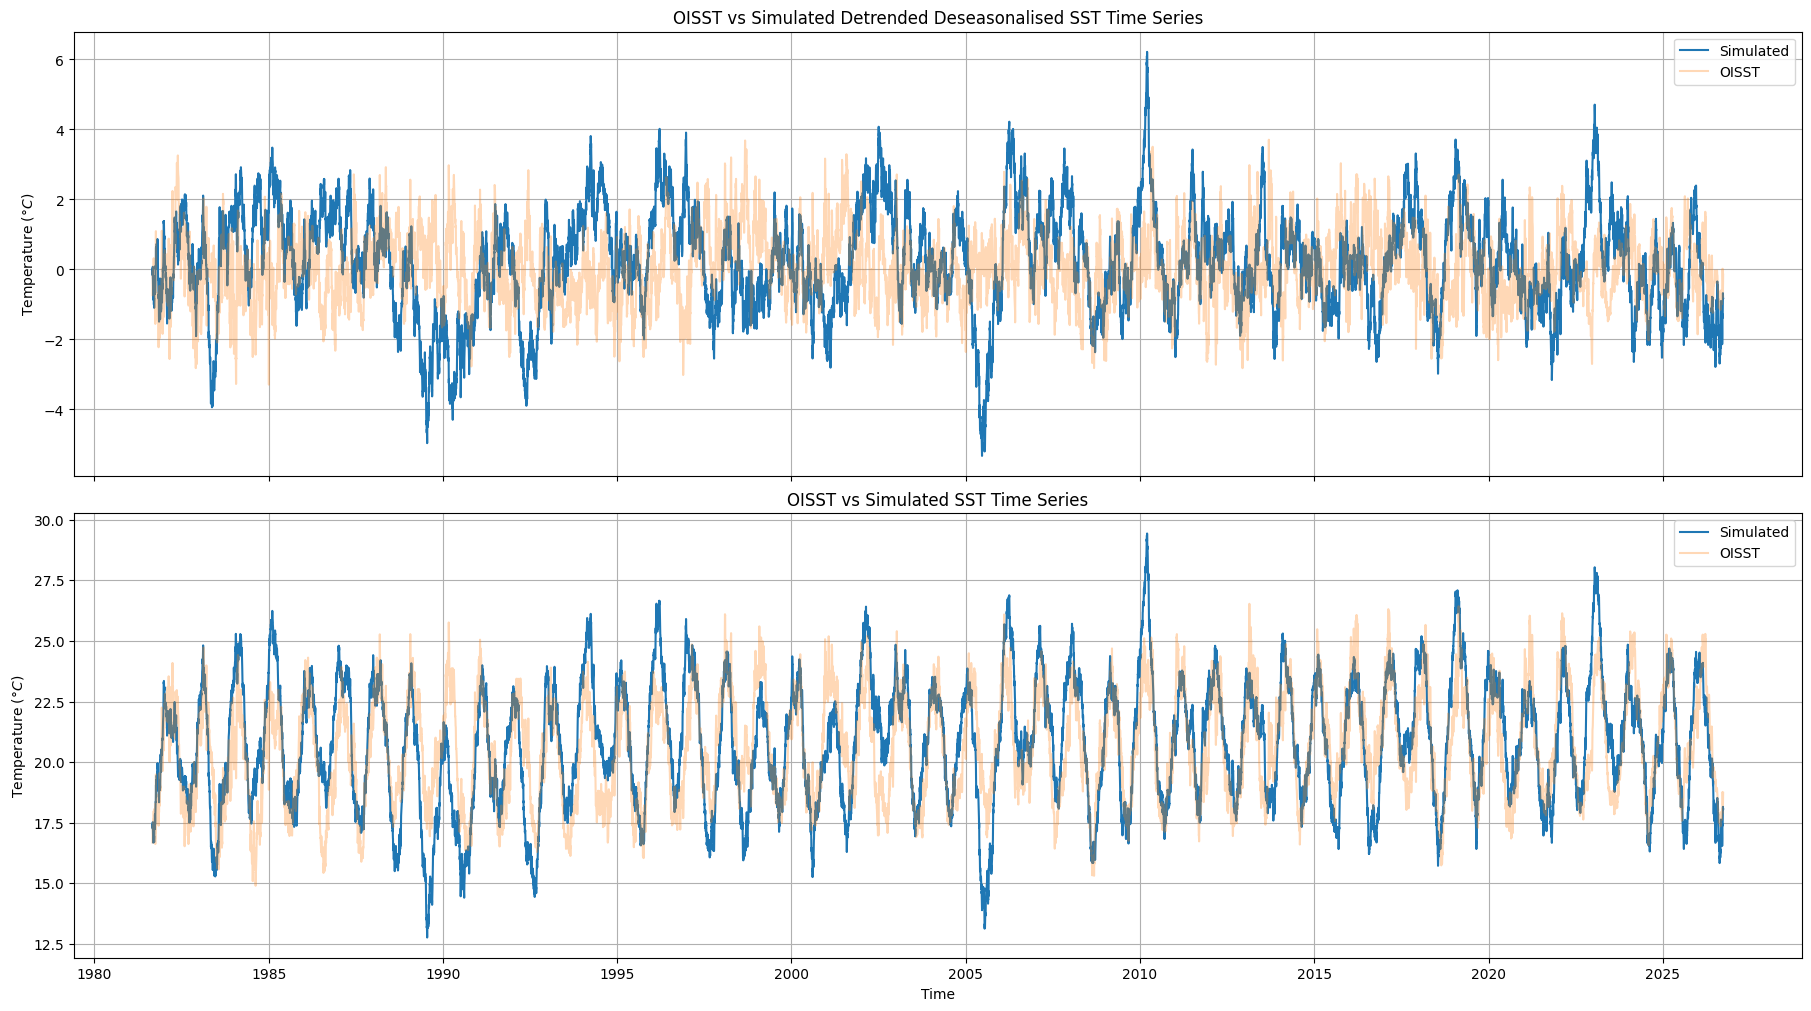

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(18, 10), sharex=True, sharey=False, constrained_layout=True)
ax1, ax2 = axes.flat[0], axes.flat[1]

# Plot OISST vs simulated Detrended Deseasonalised SST
ax1.plot(syd_daily.time, x_path, label="Simulated")
ax1.plot(syd_daily.time, syd_daily_rw, label="OISST", alpha=0.3)
ax1.set_title("OISST vs Simulated Detrended Deseasonalised SST Time Series")
ax1.set_ylabel("Temperature ($\degree C$)")
ax1.legend()
ax1.grid(True)

# Plot OISST vs simulated SST
ax2.plot(syd_daily.time, random_sst, color='tab:blue', label="Simulated")
ax2.plot(syd_daily.time, syd_daily, color='tab:orange', label="OISST", alpha=0.3)
ax2.set_title("OISST vs Simulated SST Time Series")
ax2.set_xlabel("Time")
ax2.set_ylabel("Temperature ($\degree C$)")
ax2.legend()
ax2.grid(True)

Make MHW event catalogue using simulated random

In [9]:
# # simulate damped random walk (OU process)
# t, x_path = simulate_ou_process(theta=theta_hat, sigma=sigma, x0=0, T=len(syd_daily.time), dt=dt)

# # construct simulated SST
# random_sst = (x_path + seasonality + trend).rename("temp")

# daily_rnd = resample_daily(random_sst, var="temp")
# baseline_rnd = daily_rnd.sel(time=slice("1981-09-01", "2011-09-01"))

# threshold_specs = make_threshold_specs(
#     quantiles=np.arange(0.7, 0.999, 0.001),
#     offsets=np.arange(0.0, 4.01, 0.01),
#     std_multiples=np.arange(0.0, 4.01, 0.01),
# )

# result_rnd = run_mhw_detection(
#     daily=daily_rnd,
#     baseline=baseline_rnd,
#     threshold_specs=threshold_specs,
#     pool_window=11,
#     smooth_window=31,
#     min_samples=30,
#     max_gap=2,
#     min_duration=5,
#     validate_nesting=False,
#     multiindex=True,
# )

# result_rnd["data"].to_netcdf("data/noaa_oisst/oisst_syd_events_data_RAND.nc")
# result_rnd["events"].to_pickle("data/noaa_oisst/oisst_syd_events_catalogue_RAND.pkl")

# # proc time ~ 6m 6.4s

In [10]:
# RANDOM SIMULATED OISST
mhw_events_oisst_rand = pd.read_pickle("data/noaa_oisst/oisst_syd_events_catalogue_RAND.pkl")
# mhw_all_data_oisst_rand = xr.open_dataset("data/noaa_oisst/oisst_syd_events_data_RAND.nc")

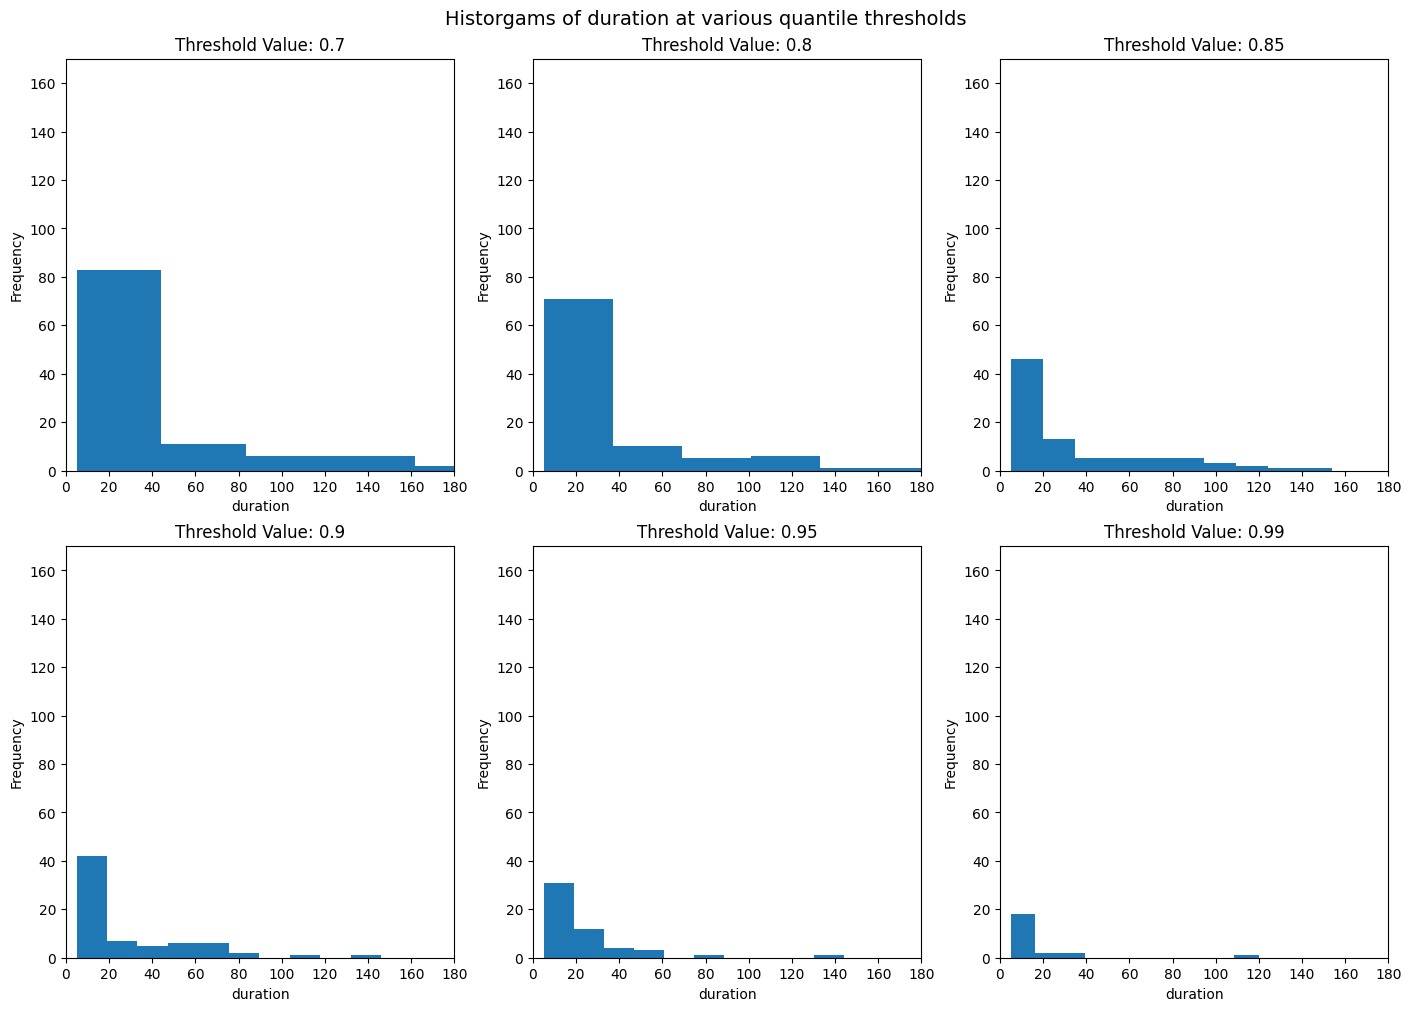

In [11]:
threshold_method = "quantile"
var = "duration"
y_var = "mean_intensity"
standardise_arrays = True

df = mhw_events_oisst_rand.xs(threshold_method, level="threshold_method").reset_index()

threshold_values_to_plot = [0.7, 0.8, 0.85, 0.9, 0.95, 0.99]

fig, axes = plt.subplots(2, 3, figsize=(14, 10), sharex=False, sharey=False, constrained_layout=True)

# Plot results for each threshold value
for ax, t_value in zip(axes.flat, threshold_values_to_plot):

    ax.hist(df.loc[(np.isclose(df["threshold_value"], t_value))][var])
    ax.set_xlabel(f"{var}")
    ax.set_ylabel("Frequency")
    ax.set_title(f"Threshold Value: {t_value}")
    ax.set_xlim((0,180))
    ax.set_ylim((0,170))

fig.suptitle(f"Historgams of {var} at various {threshold_method} thresholds", fontsize=14,)

plt.show()

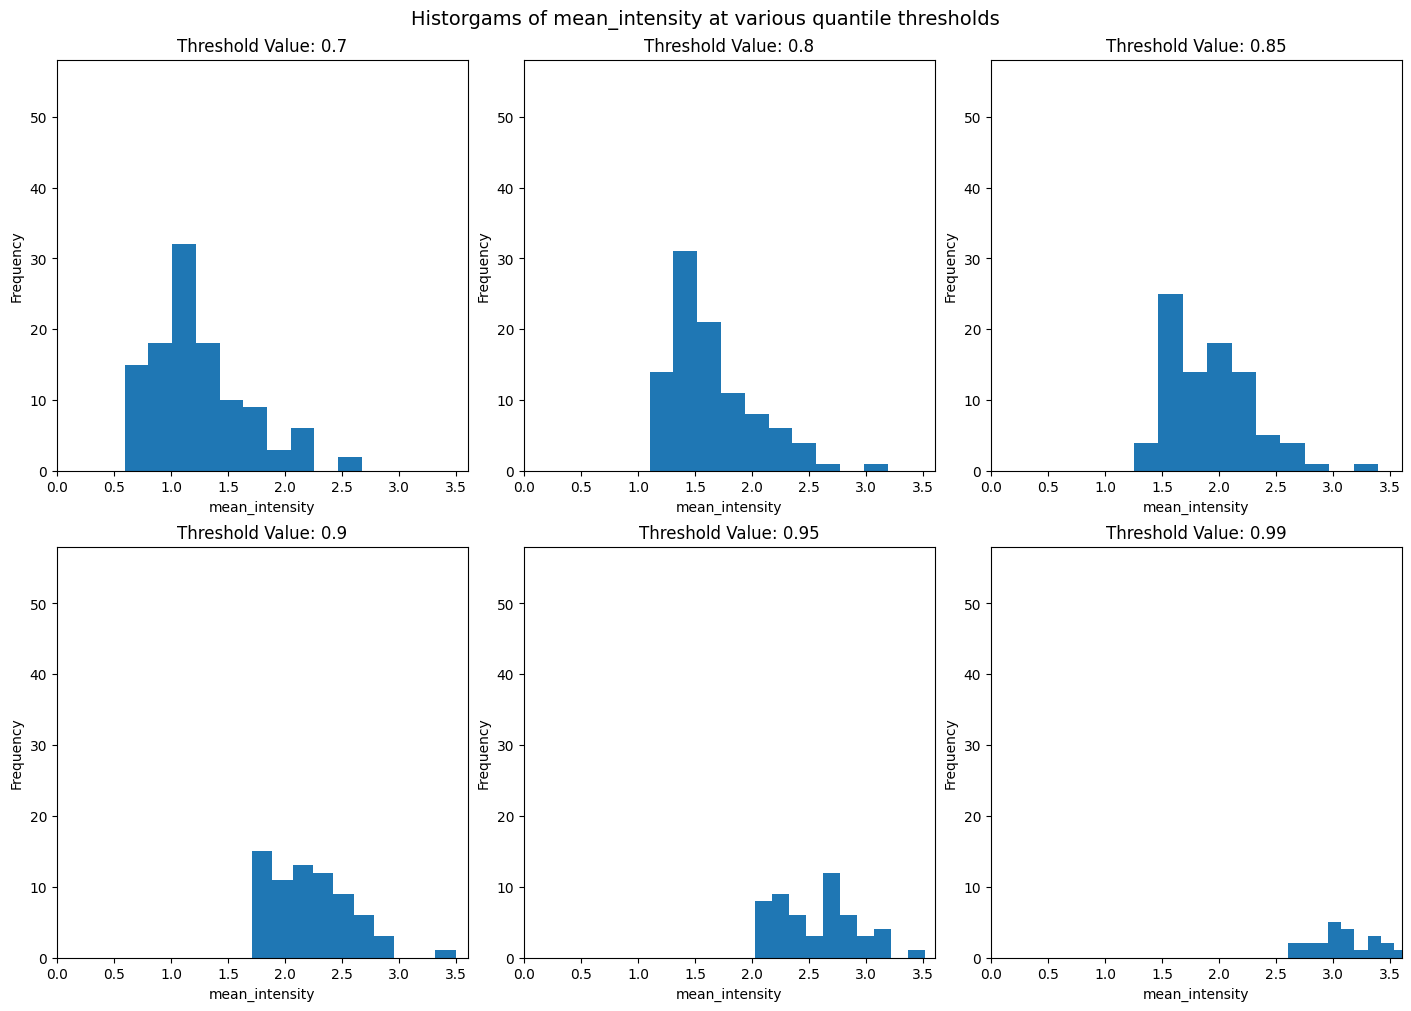

In [12]:
threshold_method = "quantile"
var = "mean_intensity"
standardise_arrays = True

df = mhw_events_oisst_rand.xs(threshold_method, level="threshold_method").reset_index()

threshold_values_to_plot = [0.7, 0.8, 0.85, 0.9, 0.95, 0.99]

fig, axes = plt.subplots(2, 3, figsize=(14, 10), sharex=False, sharey=False, constrained_layout=True)

# Plot results for each threshold value
for ax, t_value in zip(axes.flat, threshold_values_to_plot):

    ax.hist(df.loc[(np.isclose(df["threshold_value"], t_value))][var])
    ax.set_xlabel(f"{var}")
    ax.set_ylabel("Frequency")
    ax.set_title(f"Threshold Value: {t_value}")
    ax.set_xlim((0,3.6))
    ax.set_ylim((0,58))

fig.suptitle(f"Historgams of {var} at various {threshold_method} thresholds", fontsize=14,)

plt.show()

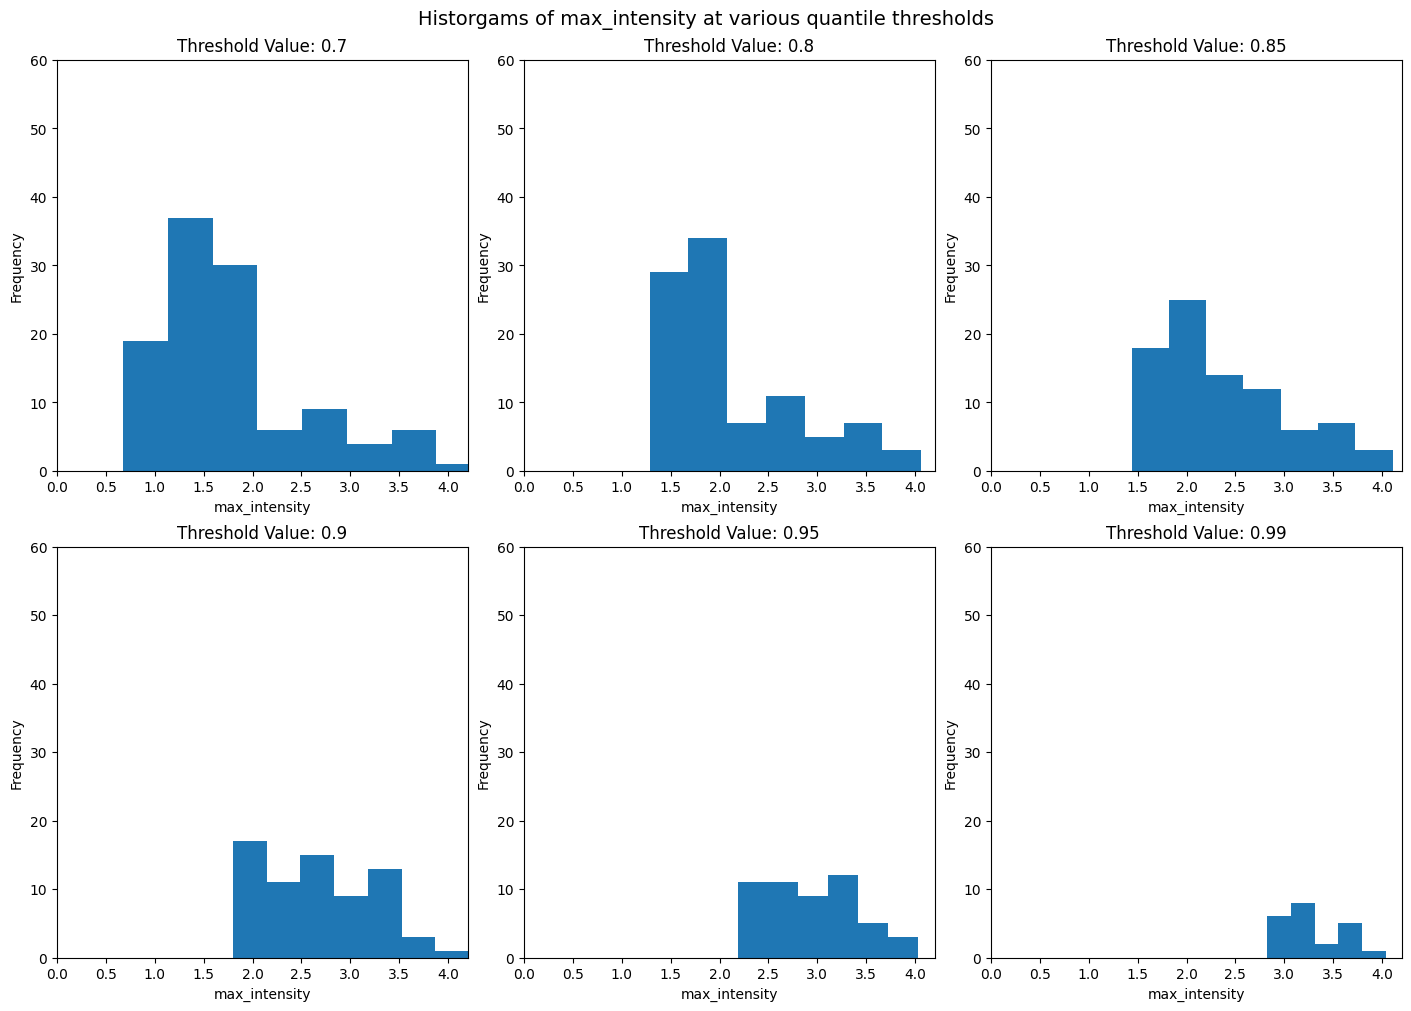

In [13]:
threshold_method = "quantile"
var = "max_intensity"
standardise_arrays = True

df = mhw_events_oisst_rand.xs(threshold_method, level="threshold_method").reset_index()

threshold_values_to_plot = [0.7, 0.8, 0.85, 0.9, 0.95, 0.99]

fig, axes = plt.subplots(2, 3, figsize=(14, 10), sharex=False, sharey=False, constrained_layout=True)

# Plot results for each threshold value
for ax, t_value in zip(axes.flat, threshold_values_to_plot):

    ax.hist(df.loc[(np.isclose(df["threshold_value"], t_value))][var])
    ax.set_xlabel(f"{var}")
    ax.set_ylabel("Frequency")
    ax.set_title(f"Threshold Value: {t_value}")
    ax.set_xlim((0, 4.2))
    ax.set_ylim((0, 60))

fig.suptitle(f"Historgams of {var} at various {threshold_method} thresholds", fontsize=14,)

plt.show()

## Production code for MHW catalogue and time series datasets

In [9]:
# var_names = {"sst": "temp"}

# daily_single = resample_daily(raw, var="temp").sel(lat=lat_sel, lon=lon_sel, method='nearest')

# baseline = daily_single.sel(time=slice("1981-09-01", "2011-09-01"))

# threshold_specs = make_threshold_specs(
#     quantiles=np.arange(0.7, 0.999, 0.001),
#     offsets=np.arange(0.0, 4.01, 0.01),
#     std_multiples=np.arange(0.0, 4.01, 0.01),
# )

# result = run_mhw_detection(
#     daily=daily_single,
#     baseline=baseline,
#     threshold_specs=threshold_specs,
#     pool_window=11,
#     smooth_window=31,
#     min_samples=30,
#     max_gap=2,
#     min_duration=5,
#     validate_nesting=False,
#     multiindex=True,
# )

# result["data"].to_netcdf("data/noaa_oisst/oisst_syd_events_data.nc")
# result["events"].to_pickle("data/noaa_oisst/oisst_syd_events_catalogue.pkl")

# proc time ~ 4m 40s
# START : 0.30 GB RSS
# AFTER  compute_climatology_stats: 0.31 GB RSS
# AFTER  build_threshold_climatology: 0.31 GB RSS
# AFTER  prepare_mhw_data: 0.38 GB RSS
# AFTER  exceedance: 0.39 GB RSS
# AFTER  raw_nesting: 0.45 GB RSS
# AFTER  detect_exceedance_events: 0.49 GB RSS
# AFTER  event_nesting: 0.50 GB RSS
# AFTER  label_exceedance_events: 0.57 GB RSS
# AFTER  compute_exceedance_event_metrics: 0.57 GB RSS
# END : 0.57 GB RSS

In [14]:
# NOAA OISST
mhw_events_oisst = pd.read_pickle("data/noaa_oisst/oisst_syd_events_catalogue.pkl")
mhw_all_data_oisst = xr.open_dataset("data/noaa_oisst/oisst_syd_events_data.nc")

## EDA: histograms of max intensity, mean intensity, and duration (to observe tails) for various thresholds

In [17]:
threshold_method = "quantile"
df = mhw_events_oisst.xs(threshold_method, level="threshold_method").reset_index()
# df.loc[df.threshold_value == 0.7]
df

,threshold_value,event_id,threshold_id,threshold_label,start_date,end_date,duration,max_intensity,max_date,mean_intensity,cumulative_intensity,rate_onset,rate_decline
0,0.700,1,0,q=0.7,1981-12-06,1981-12-13,8,1.387630,1981-12-07,0.802696,6.421566,0.614254,0.138897
1,0.700,2,0,q=0.7,1982-03-21,1982-04-03,14,1.364462,1982-03-28,0.924843,12.947800,0.099386,0.091141
2,0.700,3,0,q=0.7,1982-04-26,1982-06-09,45,2.641264,1982-05-23,1.345497,60.547363,0.070610,0.116527
3,0.700,4,0,q=0.7,1982-07-25,1982-07-29,5,0.733185,1982-07-27,0.654350,3.271749,0.047718,0.018945
4,0.700,5,0,q=0.7,1983-03-13,1983-03-20,8,0.987980,1983-03-18,0.655897,5.247179,0.061615,0.135336
...,...,...,...,...,...,...,...,...,...,...,...,...,...
49835,0.999,20,299,q=0.999,2022-02-20,2022-02-28,9,3.185190,2022-02-22,2.949842,26.548578,0.284755,0.105020
49836,0.999,21,299,q=0.999,2023-02-22,2023-02-26,5,2.641876,2023-02-25,2.565067,12.825333,0.032228,0.172329
49837,0.999,22,299,q=0.999,2024-02-23,2024-03-10,16,2.798296,2024-03-08,2.446944,39.151108,0.014106,0.106291
49838,0.999,23,299,q=0.999,2025-03-22,2025-04-05,15,2.588127,2025-03-29,2.361330,35.419945,0.053899,0.020919


In [18]:
def standardise(arr):
    return (arr - np.mean(arr)) / np.std(arr)

### Historgams at various quantile thresholds

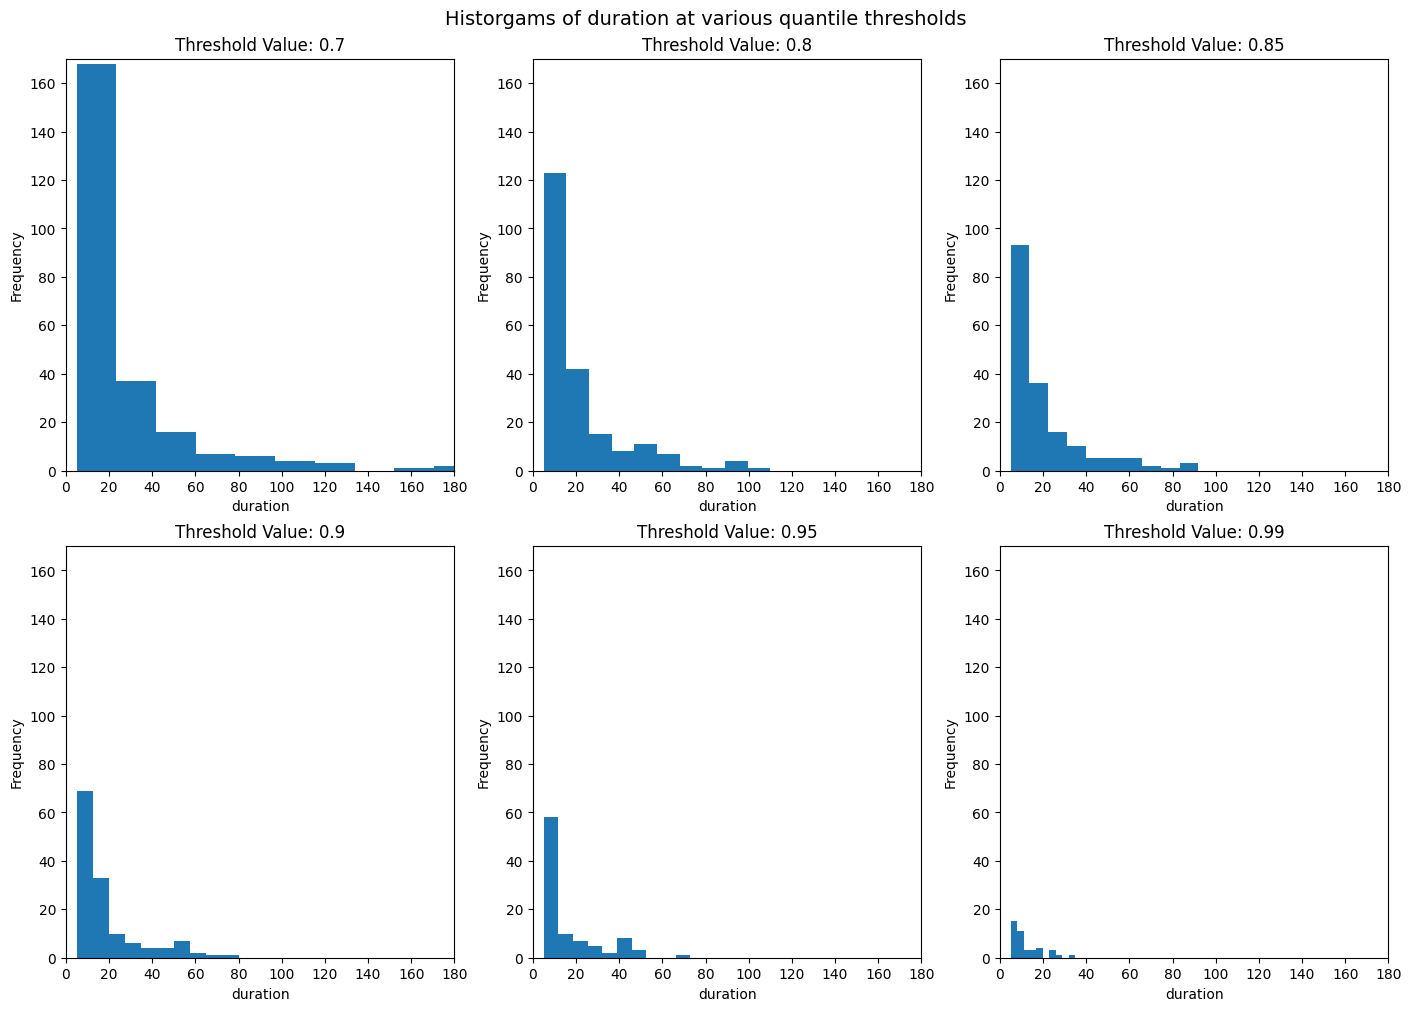

In [19]:
threshold_method = "quantile"
var = "duration"
y_var = "mean_intensity"
standardise_arrays = True

df = mhw_events_oisst.xs(threshold_method, level="threshold_method").reset_index()

threshold_values_to_plot = [0.7, 0.8, 0.85, 0.9, 0.95, 0.99]

fig, axes = plt.subplots(2, 3, figsize=(14, 10), sharex=False, sharey=False, constrained_layout=True)

# Plot results for each threshold value
for ax, t_value in zip(axes.flat, threshold_values_to_plot):

    ax.hist(df.loc[(np.isclose(df["threshold_value"], t_value))][var])
    ax.set_xlabel(f"{var}")
    ax.set_ylabel("Frequency")
    ax.set_title(f"Threshold Value: {t_value}")
    ax.set_xlim((0,180))
    ax.set_ylim((0,170))

fig.suptitle(f"Historgams of {var} at various {threshold_method} thresholds", fontsize=14,)

plt.show()

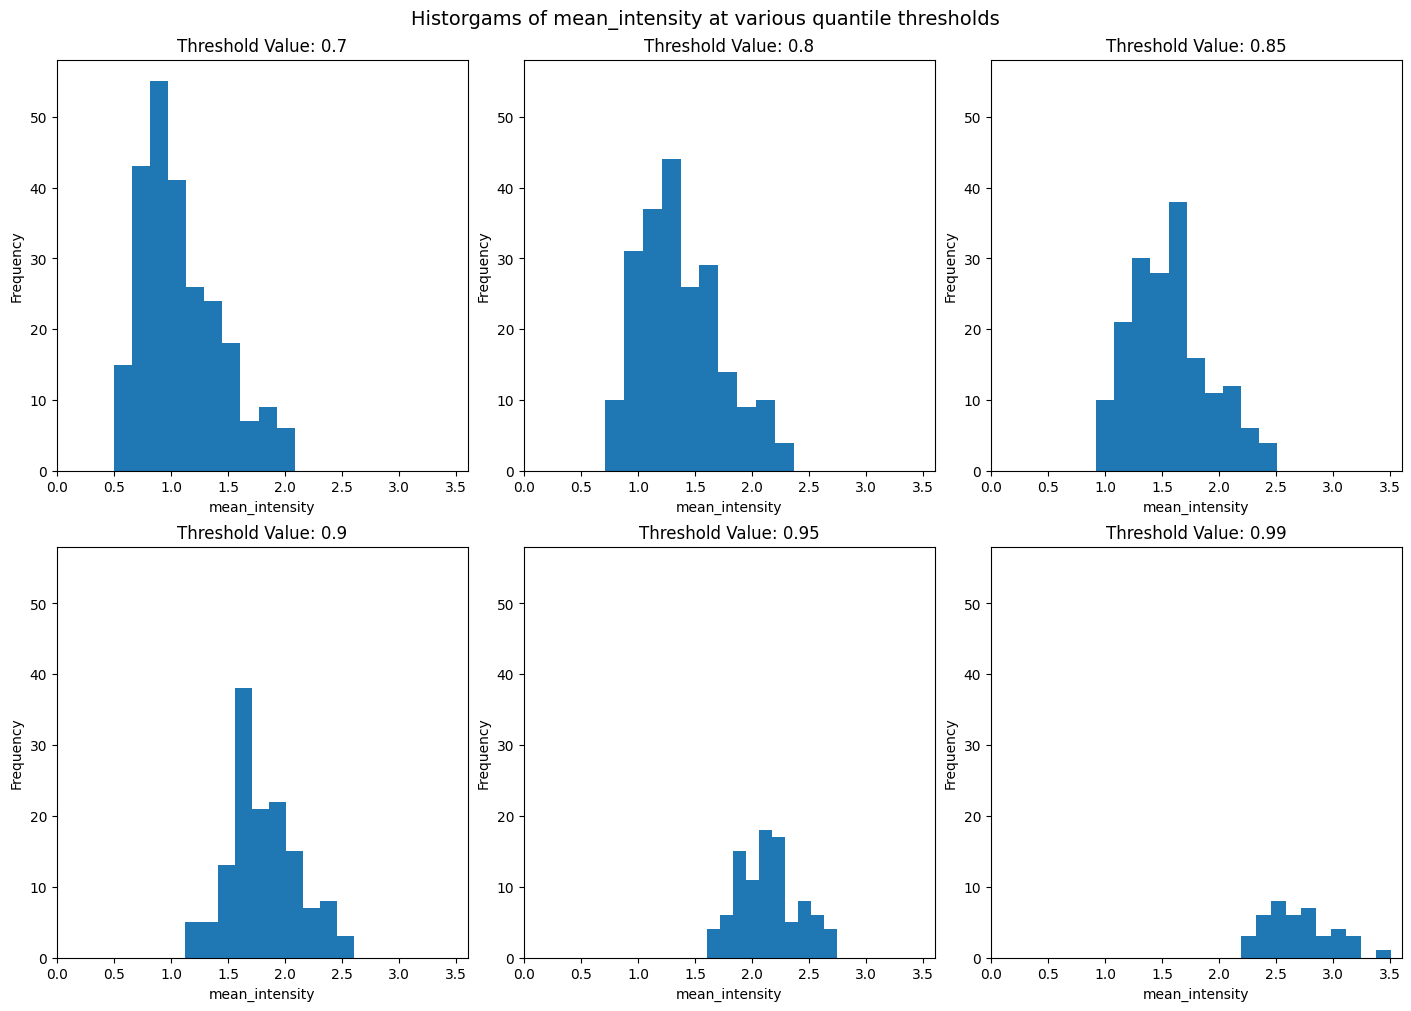

In [20]:
threshold_method = "quantile"
var = "mean_intensity"
standardise_arrays = True

df = mhw_events_oisst.xs(threshold_method, level="threshold_method").reset_index()

threshold_values_to_plot = [0.7, 0.8, 0.85, 0.9, 0.95, 0.99]

fig, axes = plt.subplots(2, 3, figsize=(14, 10), sharex=False, sharey=False, constrained_layout=True)

# Plot results for each threshold value
for ax, t_value in zip(axes.flat, threshold_values_to_plot):

    ax.hist(df.loc[(np.isclose(df["threshold_value"], t_value))][var])
    ax.set_xlabel(f"{var}")
    ax.set_ylabel("Frequency")
    ax.set_title(f"Threshold Value: {t_value}")
    ax.set_xlim((0,3.6))
    ax.set_ylim((0,58))

fig.suptitle(f"Historgams of {var} at various {threshold_method} thresholds", fontsize=14,)

plt.show()

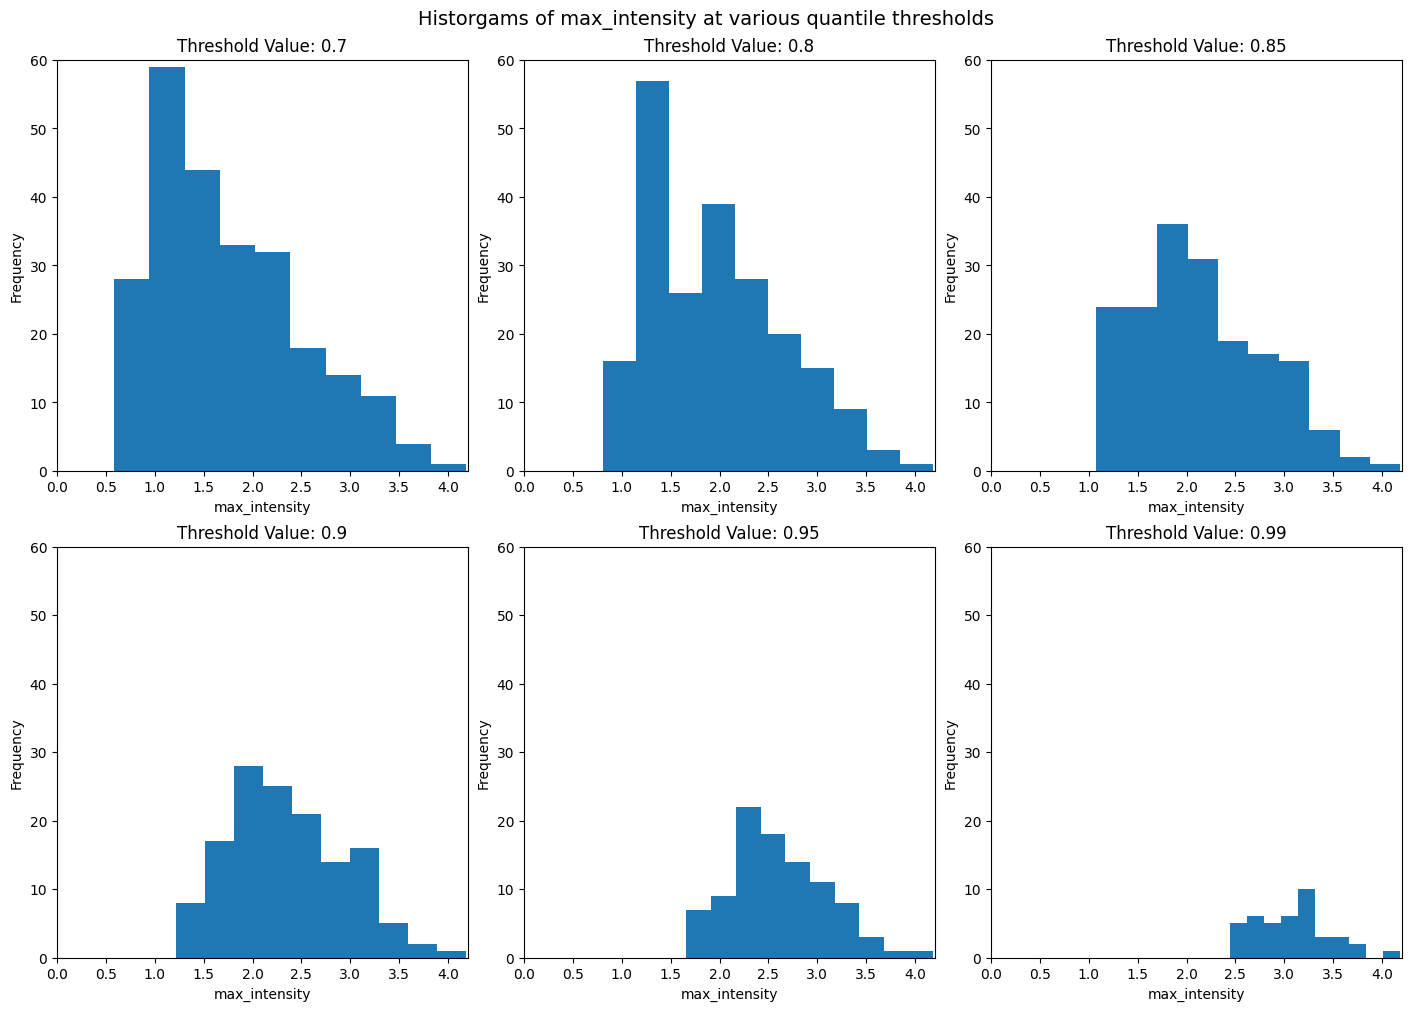

In [21]:
threshold_method = "quantile"
var = "max_intensity"
standardise_arrays = True

df = mhw_events_oisst.xs(threshold_method, level="threshold_method").reset_index()

threshold_values_to_plot = [0.7, 0.8, 0.85, 0.9, 0.95, 0.99]

fig, axes = plt.subplots(2, 3, figsize=(14, 10), sharex=False, sharey=False, constrained_layout=True)

# Plot results for each threshold value
for ax, t_value in zip(axes.flat, threshold_values_to_plot):

    ax.hist(df.loc[(np.isclose(df["threshold_value"], t_value))][var])
    ax.set_xlabel(f"{var}")
    ax.set_ylabel("Frequency")
    ax.set_title(f"Threshold Value: {t_value}")
    ax.set_xlim((0, 4.2))
    ax.set_ylim((0, 60))

fig.suptitle(f"Historgams of {var} at various {threshold_method} thresholds", fontsize=14,)

plt.show()

### What does this mean? What are the patterns?
- duration has much higher right skewness than mean intensity and max intensity
    - duration skewness remains as threshold is increased
    - max/mean intensity skewness decreases, and distribution becomes more normal, as threshold is increased

## EDA: duration-intensity scatter plots conditional threshold exceedance (for various thresholds) on standardised and non-standardised margins

### Scatter plots at various quantile thresholds

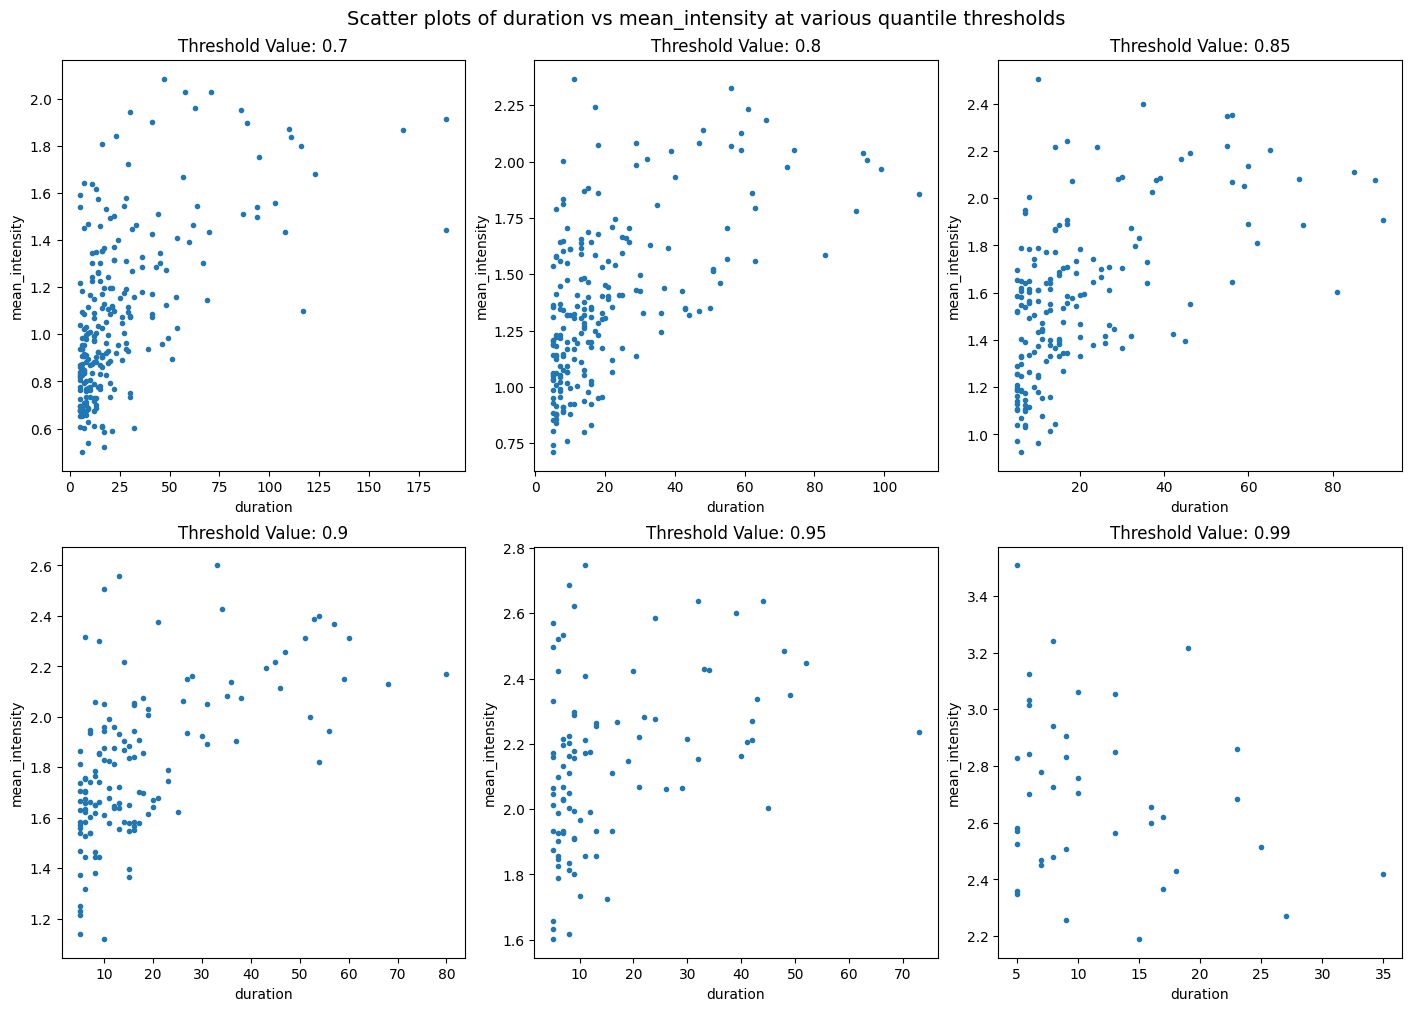

In [26]:
threshold_method = "quantile"
x_var = "duration"
y_var = "mean_intensity"
standardise_arrays = False

df = mhw_events_oisst.xs(threshold_method, level="threshold_method").reset_index()

threshold_values_to_plot = [0.7, 0.8, 0.85, 0.9, 0.95, 0.99]

fig, axes = plt.subplots(2, 3, figsize=(14, 10), sharex=False, sharey=False, constrained_layout=True)

# Plot results for each threshold value
for ax, t_value in zip(axes.flat, threshold_values_to_plot):

    df_plot = df.loc[(np.isclose(df["threshold_value"], t_value))]
    if standardise_arrays:
        ax.scatter(standardise(df_plot[x_var]), standardise(df_plot[y_var]), marker='.')
        ax.grid()
    else:
        ax.scatter(df_plot[x_var], df_plot[y_var], marker='.')
    ax.set_xlabel(f"{x_var}")
    ax.set_ylabel(f"{y_var}")
    ax.set_title(f"Threshold Value: {t_value}")
    # if not standardise_arrays:
    #     ax.set_xlim((0,180))
    #     ax.set_ylim((0,2.6))

fig.suptitle(f"Scatter plots of {x_var} vs {y_var} at various {threshold_method} thresholds", fontsize=14,)

plt.show()

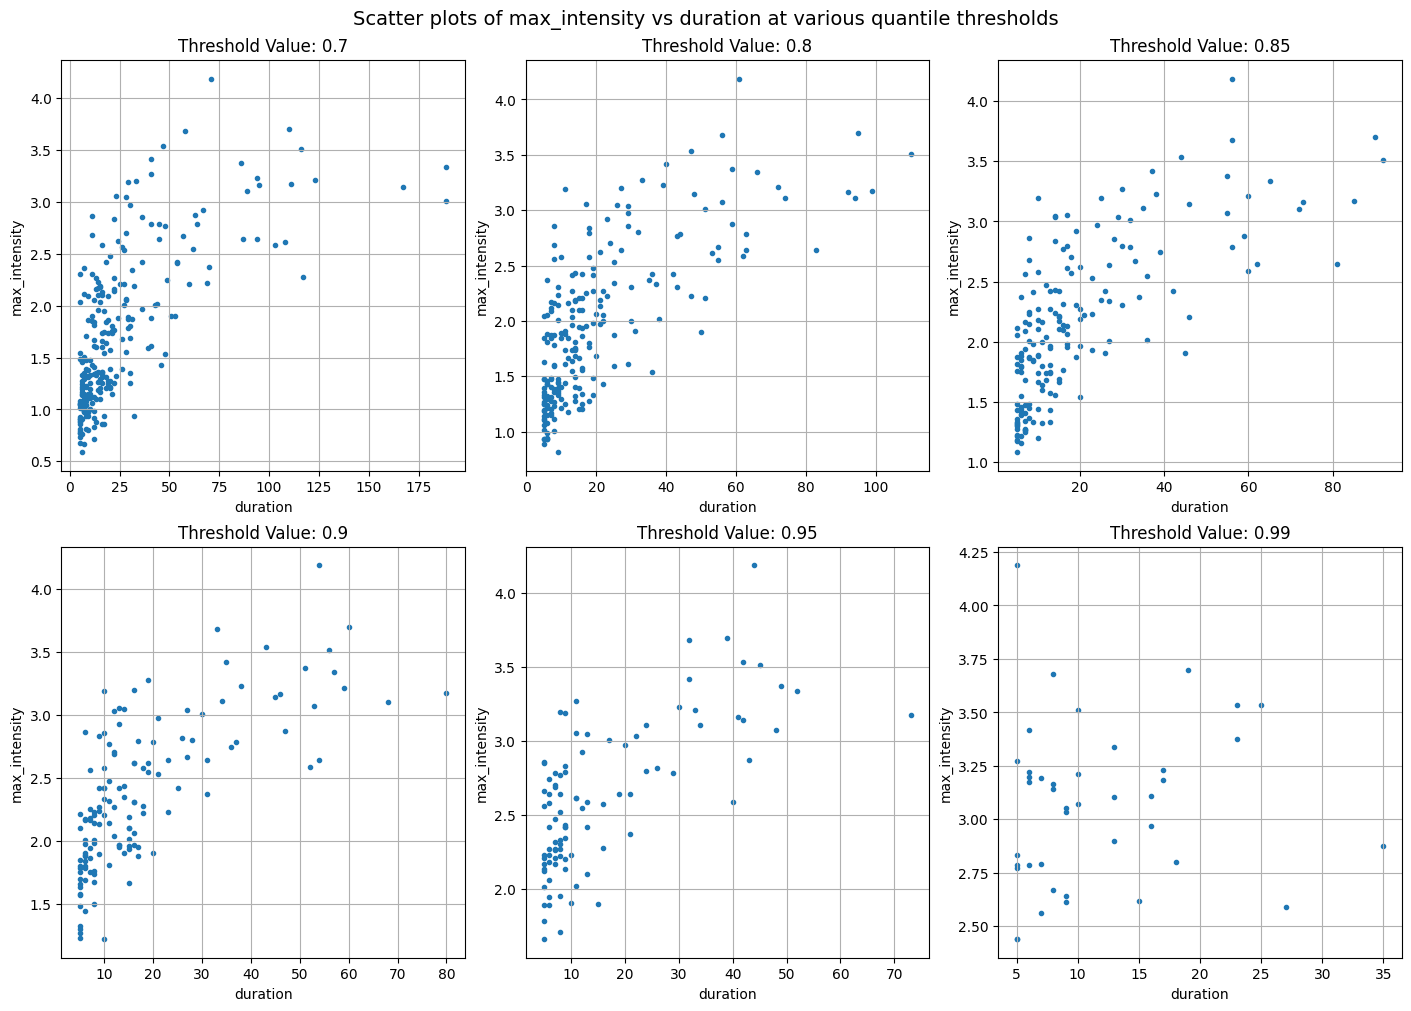

In [25]:
threshold_method = "quantile"
x_var = "duration"
y_var = "max_intensity"
standardise_arrays = False
log_xvar = False

df = mhw_events_oisst.xs(threshold_method, level="threshold_method").reset_index()

threshold_values_to_plot = [0.7, 0.8, 0.85, 0.9, 0.95, 0.99]

fig, axes = plt.subplots(2, 3, figsize=(14, 10), sharex=False, sharey=False, constrained_layout=True)

# Plot results for each quantile threshold
for ax, t_value in zip(axes.flat, threshold_values_to_plot):

    df_plot = df.loc[(np.isclose(df["threshold_value"], t_value))]
    x_var_arr = df_plot[x_var]
    y_var_arr = df_plot[y_var]

    if log_xvar:
        log_flag = "log "
        x_var_arr = np.log(df_plot[x_var])
    else:
        log_flag = ""
    if standardise_arrays:
        x_var_arr = standardise(x_var_arr)
        y_var_arr = standardise(y_var_arr)
    # else:
        # ax.set_xlim((0,180))
        # ax.set_ylim((0,4.25))
    ax.grid()
        
    ax.scatter(x_var_arr, y_var_arr, marker='.')
    ax.set_xlabel(f"{x_var}")
    ax.set_ylabel(f"{y_var}")
    ax.set_title(f"Threshold Value: {t_value}")

fig.suptitle(f"Scatter plots of {log_flag}{y_var} vs {x_var} at various {threshold_method} thresholds", fontsize=14,)

plt.show()